# 05 Price and volume

EU import value from Bangladesh is split into a price part (unit value, EUR or USD per kg) and a volume part (kg). Data: Eurostat Comext DS-045409, monthly, 2010 to the latest month. Run `python src/download_eu_quantity.py` first.

The split uses logs, so it is exact: ln(V1/V0) = ln(P1/P0) + ln(Q1/Q0). Each log term is scaled to the percentage change in value, so the two contributions add up to it.

Kg is a stand-in for the number of garments. A shift toward heavier items (jackets, denim) raises kg without more pieces, and a shift toward lighter items does the opposite. So "price" here is unit value per kg and also moves with the product mix.

The US is left out. The cached UN Comtrade US data has net weight, but it is missing for 2012-2015 and part of 2020, and in other years the implied USD/kg swings by 50-100% from year to year. The check is printed below.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
import price_volume as pv
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)
t, facts = pv.run()
cols = ["period", "value", "qty_kg", "unit_value", "value_chg_pct", "price_chg_pct", "volume_chg_pct", "price_contrib_pp", "volume_contrib_pp"]
tot = t[(t.currency == "EUR") & (t["product"] == "TOTAL")]
tot[cols].round(2)

,period,value,qty_kg,unit_value,value_chg_pct,price_chg_pct,volume_chg_pct,price_contrib_pp,volume_contrib_pp
22,2025 Jan-Aug,1.350451e+10,9.083741e+08,14.87,NaN,NaN,NaN,NaN,NaN
23,2026 Jan-Aug,1.192799e+10,8.667589e+08,13.76,-11.67,-7.43,-4.58,-7.26,-4.41
176,2010,5.233683e+09,5.368077e+08,9.75,NaN,NaN,NaN,NaN,NaN
177,2011,6.786797e+09,5.715492e+08,11.87,29.68,21.79,6.47,22.51,7.16
178,2012,7.418148e+09,6.021365e+08,12.32,9.30,3.75,5.35,3.85,5.45
179,2013,8.211739e+09,7.403229e+08,11.09,10.70,-9.96,22.95,-11.05,21.75
180,2014,9.365157e+09,8.010311e+08,11.69,14.05,5.40,8.20,5.62,8.42
181,2015,1.153634e+10,8.411063e+08,13.72,23.18,17.31,5.00,17.76,5.43
182,2016,1.258751e+10,9.331463e+08,13.49,9.11,-1.65,10.94,-1.74,10.85
183,2017,1.292705e+10,9.603336e+08,13.46,2.70,-0.21,2.91,-0.21,2.91


## Was the 2023 drop fewer garments or cheaper garments?

In [2]:
tot[tot.year.isin([2022, 2023]) & (tot.months == 12)][cols].round(2)

,period,value,qty_kg,unit_value,value_chg_pct,price_chg_pct,volume_chg_pct,price_contrib_pp,volume_contrib_pp
188,2022,2.191887e+10,1.334780e+09,16.42,53.33,25.65,22.03,28.49,24.85
189,2023,1.744982e+10,1.117205e+09,15.62,-20.39,-4.88,-16.30,-4.48,-15.91


Mostly fewer kg. EU imports fell 20.4% in EUR in 2023. Kg fell 16.3% and EUR per kg fell 4.9%, so about 16 of the 20 points came from volume. In USD the fall was 18.0%, and only 2 points of that came from unit value.

## The 2022 peak: price or volume?

In [3]:
usd = t[(t.currency == "USD") & (t["product"] == "TOTAL") & (t.year == 2022) & (t.months == 12)]
pd.concat([tot[(tot.year == 2022) & (tot.months == 12)], usd])[["currency"] + cols].round(2)

,currency,period,value,qty_kg,unit_value,value_chg_pct,price_chg_pct,volume_chg_pct,price_contrib_pp,volume_contrib_pp
188,EUR,2022,2.191887e+10,1.334780e+09,16.42,53.33,25.65,22.03,28.49,24.85
188,USD,2022,2.300311e+10,1.334780e+09,17.23,36.30,11.69,22.03,12.95,23.34


Both, with the answer depending on the currency. In EUR, value rose 53.3%: kg up 22.0% and EUR per kg up 25.6%, so price was slightly the bigger part (28.5 points against 24.8). Much of that EUR price rise is the weak euro in 2022. In USD, unit value rose only 11.7% and volume was the larger part. The 2023 EUR unit value stayed above the 2021 level, so part of the 2022 price gain held.

## Unit value by chapter and product

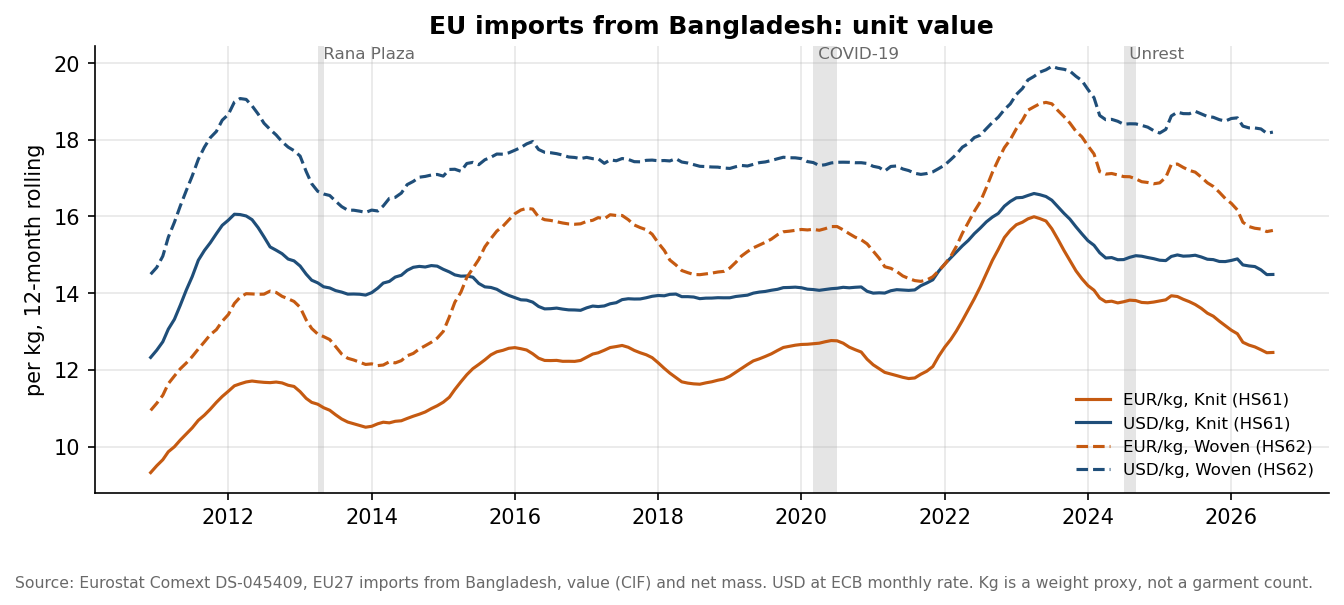

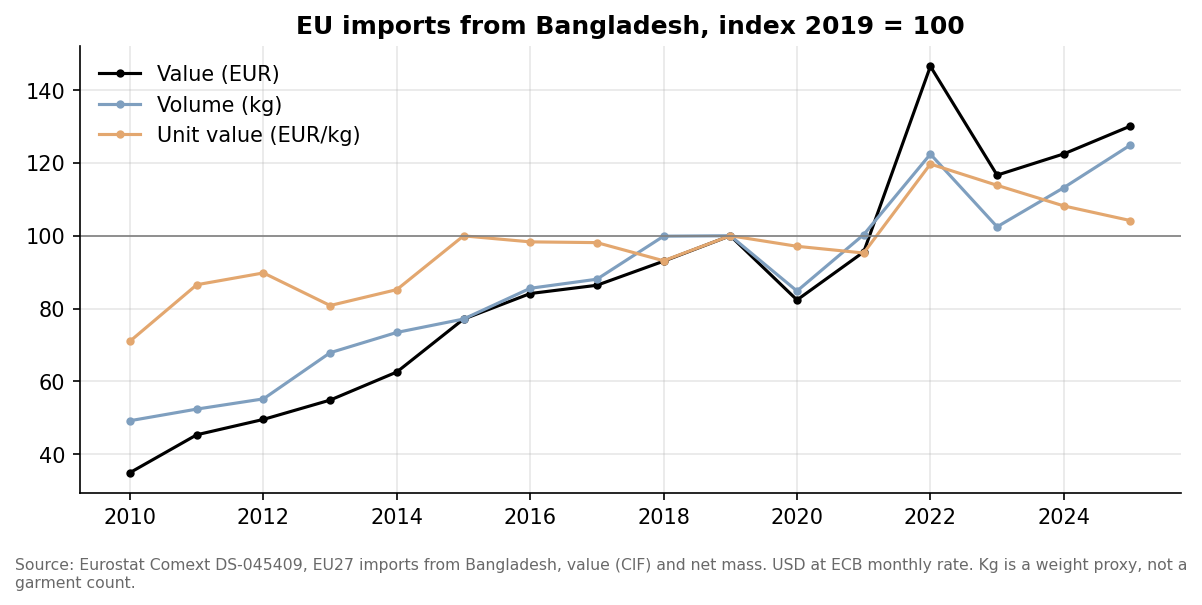

In [4]:
display(Image(ROOT / "outputs/figures/fig_pv01_unit_value_trend.png"))
display(Image(ROOT / "outputs/figures/fig_pv04_eu_index_value_volume_price.png"))

In [5]:
p = t[(t.currency == "EUR") & (t.months == 12) & t.year.isin([2019, 2022, 2025])]
p.pivot(index="product_name", columns="year", values="unit_value").round(2)

year,2019,2022,2025
product_name,,,
Knit (HS61),12.64,15.64,13.15
Men's coats (6201),15.35,19.30,18.52
Men's knit shirts (6105),12.68,16.21,14.66
Men's trousers/suits (6203),13.80,16.28,14.59
Men's woven shirts (6205),18.29,21.62,22.37
Sweaters (6110),13.82,16.19,13.26
T-shirts (6109),11.11,14.11,12.08
Total HS61+62,13.72,16.42,14.29
Women's coats (6202),16.08,20.78,18.19


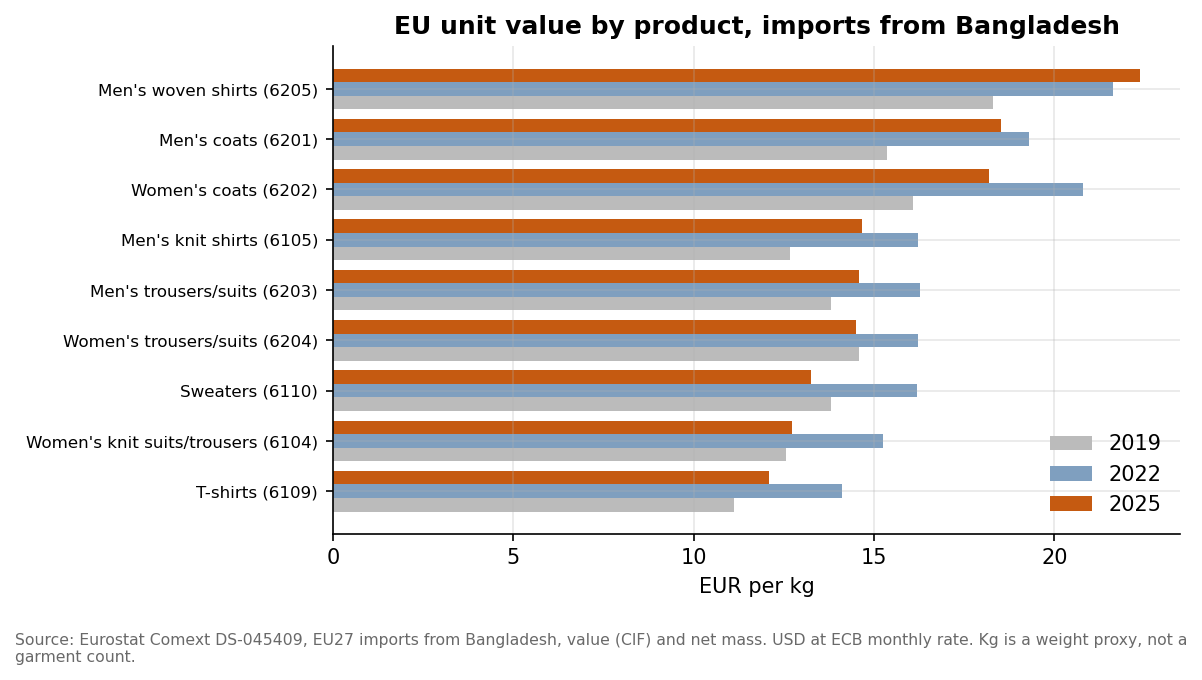

In [6]:
display(Image(ROOT / "outputs/figures/fig_pv03_eu_unit_value_by_product.png"))

## Year-by-year split

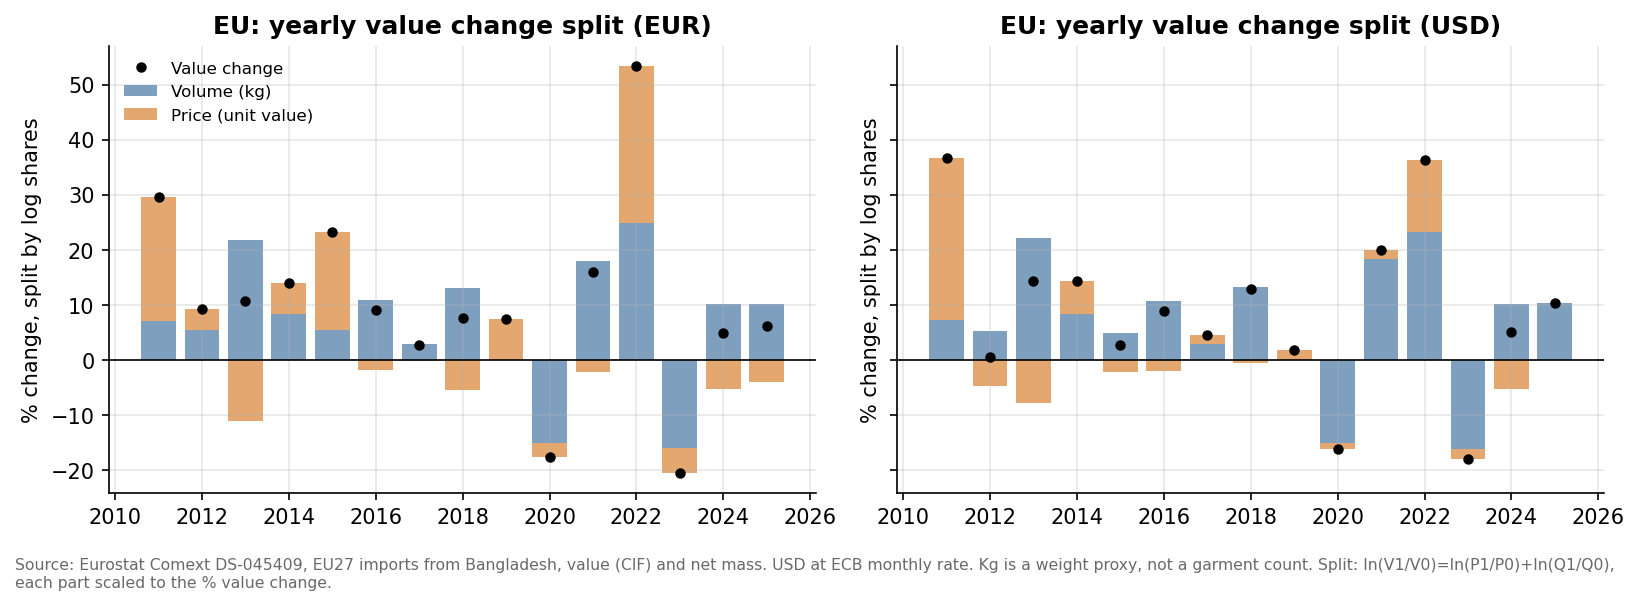

In [7]:
display(Image(ROOT / "outputs/figures/fig_pv02_yoy_price_volume_split.png"))

## US weight check (not used)

In [8]:
pd.read_csv(ROOT / "outputs/tables/price_volume_us_weight_check.csv")

,year,value_usd,qty_kg,unit_value,value_share_with_weight
0,2010,NaN,NaN,NaN,0.8534
1,2011,4.566581e+09,2.801409e+08,16.3010,1.0000
2,2012,NaN,NaN,NaN,0.0000
3,2013,NaN,NaN,NaN,0.0000
4,2014,NaN,NaN,NaN,0.0000
5,2015,NaN,NaN,NaN,0.0000
6,2016,5.308777e+09,1.788505e+08,29.6828,1.0000
7,2017,5.061815e+09,1.767730e+08,28.6346,1.0000
8,2018,5.429200e+09,1.837002e+08,29.5547,1.0000
9,2019,5.928627e+09,2.387420e+08,24.8328,1.0000


## Competitors

No competitor unit values are compared here. The cached competitor files (data/raw/competitors) are US imports by value only, with no EU quantities.

## Key facts

In [9]:
facts

,fact,value,unit,method
0,EU 2023 value change (EUR),-20.39,%,"Volume (kg) -16.3%, unit value EUR/kg -4.9%. Of the -20.4% fall, -15.9 pp is volume and -4.5 pp is price (log shares). HS61+62, 2023 vs 2022."
1,EU 2022 value change (EUR),53.33,%,"Volume +22.0%, unit value +25.6%; 28.5 pp price, 24.8 pp volume. 2022 vs 2021."
2,EU 2022 unit value change in USD,11.69,%,"In USD the 2022 unit value rose 11.7% against 25.6% in EUR; the euro fell against the dollar. Value in USD +36.3%, volume +22.0%."
3,EU unit value 2025 vs 2019 (EUR/kg),4.16,%,13.72 EUR/kg in 2019 to 14.29 in 2025; kg +24.9% over the same years.
4,"EU 2026 Jan-Aug value change (EUR, vs same months a year earlier)",-11.67,%,"Volume -4.6%, unit value -7.4%; -7.3 pp price, -4.4 pp volume. Provisional months."
